# Train a tiny SAE on a synthetic feature manifold

**Question.** Can a new dictionary preserve a small circle when much larger variation is present?

We generate miniature activations with a planted two-coordinate circle and a separate high-amplitude direction. The same unlabeled training rows go into both models. The planted coordinates are available for evaluation. The full project trains separate dictionaries on millions of frozen GPT-2 residual presentations. [Project results](../RESULTS.md#what-the-new-autoencoders-recovered) · [Goodfire on SAEs and neural geometry](https://www.goodfire.com/research/can-saes-capture-neural-geometry)

In [1]:
%matplotlib inline
import numpy as np
import torch
import matplotlib.pyplot as plt

torch.set_num_threads(1)
rng = np.random.default_rng(654)
dimension, width, k = 24, 64, 4
mixing, _ = np.linalg.qr(rng.normal(size=(dimension, dimension)))

def make_rows(count, generator):
    theta = generator.uniform(0, 2 * np.pi, count)
    signal = np.column_stack([np.cos(theta), np.sin(theta)])
    latent = generator.normal(0, 0.15, size=(count, dimension))
    latent[:, :2] += signal
    giant = generator.uniform(size=count) < 0.1
    latent[giant, 2] += generator.normal(0, 13, giant.sum())
    latent[:, 3] += generator.normal(0, 1.5, count)
    return (latent @ mixing.T).astype("float32"), signal

train, _ = make_rows(2500, rng)
test, true_coordinates = make_rows(600, np.random.default_rng(217))
center = train.mean(axis=0)
scale = np.sqrt(np.mean((train - center) ** 2))
train_tensor = torch.from_numpy((train - center) / scale)
test_tensor = torch.from_numpy((test - center) / scale)
print(f"Train {train.shape}; held out {test.shape}; input RMS scale {scale:.2f}")

Train (2500, 24); held out (600, 24); input RMS scale 0.89


## Use the same dictionary size and sparsity

The encoder creates 64 candidate coefficients. TopK keeps four per example, and ReLU keeps the selected values nonnegative. The decoder reconstructs the input using the retained values.

MSE gives each squared error equal weight. The second objective divides each example's squared error by its squared input size with a small floor. Both runs start from the same initialization and see the same batches.

In [2]:
class TinySAE(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = torch.nn.Linear(dimension, width)
        self.decoder = torch.nn.Linear(width, dimension)

    def forward(self, x):
        scores = self.encoder(x)
        values, indices = scores.topk(k, dim=1)
        sparse = torch.zeros_like(scores).scatter(1, indices, values.relu())
        return self.decoder(sparse)

def train_sae(relative):
    torch.manual_seed(111)
    model = TinySAE()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.003)
    steps = np.random.default_rng(43).integers(0, len(train_tensor), size=(560, 96))
    for indexes in steps:
        batch = train_tensor[indexes]
        error = (model(batch) - batch).square().mean(dim=1)
        if relative:
            error = error / batch.square().mean(dim=1).clamp_min(0.05)
        optimizer.zero_grad()
        error.mean().backward()
        optimizer.step()
    return model

models = {"Global MSE": train_sae(False), "Relative per token": train_sae(True)}

## Check overall error and the planted geometry

The same two ground-truth coordinates are read from each reconstruction. A metric averaged over all residual energy can reward preserving the largest direction. Check the angular error directly when the feature geometry is what you care about.

Global MSE           global FVU 0.027 · mean angle error 15.0°
Relative per token   global FVU 0.024 · mean angle error 12.2°


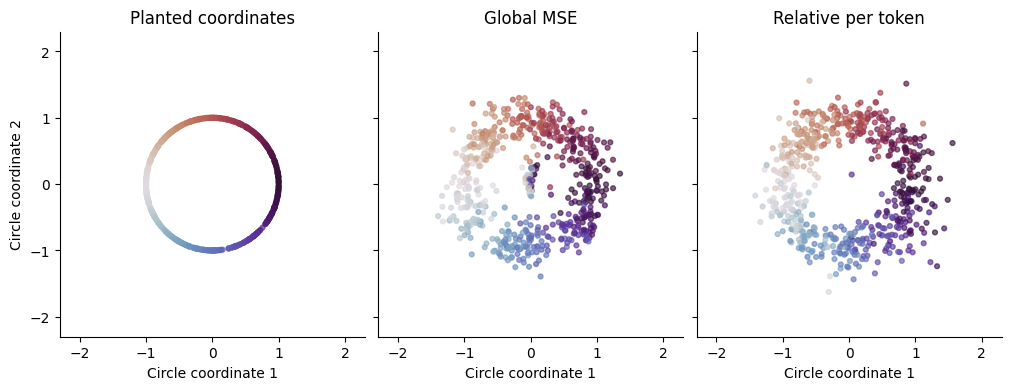

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.6), sharex=True, sharey=True, layout="constrained")
angles = np.arctan2(true_coordinates[:, 1], true_coordinates[:, 0])
phase = np.exp(1j * angles)
outputs = {"Planted coordinates": true_coordinates}
with torch.inference_mode():
    for name, model in models.items():
        decoded = model(test_tensor).numpy() * scale + center
        points = decoded @ mixing[:, :2]
        outputs[name] = points
        error = np.square(test - decoded).mean(axis=1)
        energy = np.square(test - center).mean(axis=1)
        guessed = points[:, 0] + 1j * points[:, 1]
        mean_angle = np.degrees(np.abs(np.angle(guessed * phase.conj())).mean())
        print(f"{name:20s} global FVU {error.sum()/energy.sum():.3f} · mean angle error {mean_angle:.1f}°")

for ax, (name, points) in zip(axes, outputs.items(), strict=True):
    ax.scatter(*points.T, c=angles, cmap="twilight", s=12, alpha=0.65)
    ax.set(title=name, xlabel="Circle coordinate 1", xlim=(-2.3, 2.3), ylim=(-2.3, 2.3))
    ax.set_aspect("equal")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Circle coordinate 2")
plt.show()

**Try it.** Change the burst size from 13 to 4, or keep eight latents instead of four. Both changes alter the competition for capacity. The effect in this toy run is tied to the planted structure, initialization, and capacity. The real comparison repeats every loss under three seeds and tests on distinct corpora.

[Real-data comparison](../RESULTS.md#what-the-new-autoencoders-recovered)